In [1]:
!pip install rasterio

In [2]:
import rasterio
import rasterio.enums
import matplotlib.pyplot as plt
import numpy as np
import gc
import cv2
import pandas as pd
import geopandas as gpd
from rasterio.mask import mask
import re
from shapely.geometry import mapping
from tqdm import tqdm
from shapely.geometry import Polygon

import os
from glob import glob
import json

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Pre-Processing Images**

## **Extracting Preliminary Information**

In [4]:
# Extracting List of Images
IMG_DIR = "/content/drive/MyDrive/Stack_Termal_B10_Landsat_9"

tif_files = sorted([f for f in os.listdir(IMG_DIR) if f.lower().endswith(".tif")])

print(f"Existing Images TIFF: {len(tif_files)}\n")
for f in tif_files:
    print(f)

Existing Images TIFF: 35

L9_Banda10_LC09_L1GT_230070_20250110_20250110_02_T2.tif
L9_Banda10_LC09_L1GT_230070_20250227_20250227_02_T2.tif
L9_Banda10_LC09_L1GT_230070_20250416_20250416_02_T2.tif
L9_Banda10_LC09_L1GT_230071_20250110_20250110_02_T2.tif
L9_Banda10_LC09_L1GT_230071_20250227_20250227_02_T2.tif
L9_Banda10_LC09_L1GT_230072_20250110_20250110_02_T2.tif
L9_Banda10_LC09_L1GT_230072_20250227_20250227_02_T2.tif
L9_Banda10_LC09_L1GT_230072_20250416_20250416_02_T2.tif
L9_Banda10_LC09_L1GT_230072_20250619_20250619_02_T2.tif
L9_Banda10_LC09_L1GT_231070_20250218_20250218_02_T2.tif
L9_Banda10_LC09_L1GT_231070_20250306_20250306_02_T2.tif
L9_Banda10_LC09_L1GT_231071_20250202_20250202_02_T2.tif
L9_Banda10_LC09_L1GT_231072_20250218_20250218_02_T2.tif
L9_Banda10_LC09_L1GT_231072_20250423_20250423_02_T2.tif
L9_Banda10_LC09_L1GT_231073_20250423_20250423_02_T2.tif
L9_Banda10_LC09_L1GT_232070_20250108_20250108_02_T2.tif
L9_Banda10_LC09_L1GT_232070_20250209_20250209_02_T2.tif
L9_Banda10_LC09_L1GT_2

In [5]:
# Extracting Metadata
GEOJSON_PATH = "/content/drive/MyDrive/Stack_Termal_B10_Landsat_9/L9_Banda10_Metadata_2025_10.geojson"

gdf = gpd.read_file(GEOJSON_PATH)

print("Number of Images Data:", len(gdf))
gdf.head()

Number of Images Data: 35


,id,CLOUD_COVER,CLOUD_COVER_LAND,COLLECTION_CATEGORY,COLLECTION_NUMBER,DATA_SOURCE_ELEVATION,DATE_ACQUIRED,DATE_PRODUCT_GENERATED,DATUM,EARTH_SUN_DISTANCE,...,export_name,overlap,productId,system:asset_size,system:footprint,system:id,system:time_end,system:time_start,system:version,geometry
0,LC09_230070_20250110,98.92,98.92,T2,2.0,GLS2000,2025-01-10,1.736527e+12,WGS84,0.983418,...,L9_Banda10_LC09_L1GT_230070_20250110_20250110_...,0.997245,LC09_L1GT_230070_20250110_20250110_02_T2,1349954246,"{'type': 'LineString', 'coordinates': [[-62.15...",LANDSAT/LC09/C02/T2/LC09_230070_20250110,1.736518e+12,1.736518e+12,1736634402891668,MULTIPOINT EMPTY
1,LC09_230070_20250227,92.80,92.80,T2,2.0,GLS2000,2025-02-27,1.740674e+12,WGS84,0.990498,...,L9_Banda10_LC09_L1GT_230070_20250227_20250227_...,0.997335,LC09_L1GT_230070_20250227_20250227_02_T2,1373286388,"{'type': 'LineString', 'coordinates': [[-60.96...",LANDSAT/LC09/C02/T2/LC09_230070_20250227,1.740665e+12,1.740665e+12,1740824704634626,MULTIPOINT EMPTY
2,LC09_230070_20250416,67.42,67.42,T2,2.0,GLS2000,2025-04-16,1.744821e+12,WGS84,1.003606,...,L9_Banda10_LC09_L1GT_230070_20250416_20250416_...,0.998001,LC09_L1GT_230070_20250416_20250416_02_T2,1337596162,"{'type': 'LineString', 'coordinates': [[-60.86...",LANDSAT/LC09/C02/T2/LC09_230070_20250416,1.744813e+12,1.744813e+12,1744930625715316,MULTIPOINT EMPTY
3,LC09_230071_20250110,100.00,100.00,T2,2.0,GLS2000,2025-01-10,1.736527e+12,WGS84,0.983418,...,L9_Banda10_LC09_L1GT_230071_20250110_20250110_...,1.000000,LC09_L1GT_230071_20250110_20250110_02_T2,1329000814,"{'type': 'LineString', 'coordinates': [[-61.15...",LANDSAT/LC09/C02/T2/LC09_230071_20250110,1.736518e+12,1.736518e+12,1736634424963920,MULTIPOINT EMPTY
4,LC09_230071_20250227,99.99,99.99,T2,2.0,GLS2000,2025-02-27,1.740674e+12,WGS84,0.990498,...,L9_Banda10_LC09_L1GT_230071_20250227_20250227_...,1.000000,LC09_L1GT_230071_20250227_20250227_02_T2,1270324884,"{'type': 'LineString', 'coordinates': [[-62.47...",LANDSAT/LC09/C02/T2/LC09_230071_20250227,1.740665e+12,1.740665e+12,1740824650589515,MULTIPOINT EMPTY


In [6]:
gdf.describe(include='all')

,id,CLOUD_COVER,CLOUD_COVER_LAND,COLLECTION_CATEGORY,COLLECTION_NUMBER,DATA_SOURCE_ELEVATION,DATE_ACQUIRED,DATE_PRODUCT_GENERATED,DATUM,EARTH_SUN_DISTANCE,...,export_name,overlap,productId,system:asset_size,system:footprint,system:id,system:time_end,system:time_start,system:version,geometry
count,35,35.000000,35.000000,35,35.0,35,35,3.500000e+01,35,35.000000,...,35,35.000000,35,3.500000e+01,35,35,3.500000e+01,3.500000e+01,3.500000e+01,35
unique,35,NaN,NaN,1,NaN,1,NaN,NaN,1,NaN,...,35,NaN,35,NaN,35,35,NaN,NaN,NaN,1
top,LC09_230070_20250110,NaN,NaN,T2,NaN,GLS2000,NaN,NaN,WGS84,NaN,...,L9_Banda10_LC09_L1GT_230070_20250110_20250110_...,NaN,LC09_L1GT_230070_20250110_20250110_02_T2,NaN,"{'type': 'LineString', 'coordinates': [[-62.15...",LANDSAT/LC09/C02/T2/LC09_230070_20250110,NaN,NaN,NaN,MULTIPOINT EMPTY
freq,1,NaN,NaN,35,NaN,35,NaN,NaN,35,NaN,...,1,NaN,1,NaN,1,1,NaN,NaN,NaN,35
mean,NaN,86.466286,86.466286,NaN,2.0,NaN,2025-03-04 11:39:25.714000,1.741157e+12,NaN,0.993389,...,NaN,0.995230,NaN,1.323176e+09,NaN,NaN,1.741140e+12,1.741140e+12,1.741262e+15,NaN
min,NaN,15.030000,15.030000,NaN,2.0,NaN,2025-01-01 00:00:00,1.735756e+12,NaN,0.983345,...,NaN,0.956838,NaN,1.186822e+09,NaN,NaN,1.735741e+12,1.735741e+12,1.735856e+15,NaN
25%,NaN,78.875000,78.875000,NaN,2.0,NaN,2025-01-24 00:00:00,1.737744e+12,NaN,0.984627,...,NaN,0.997290,NaN,1.312213e+09,NaN,NaN,1.737729e+12,1.737729e+12,1.737844e+15,NaN
50%,NaN,93.810000,93.810000,NaN,2.0,NaN,2025-02-27 00:00:00,1.740674e+12,NaN,0.990498,...,NaN,1.000000,NaN,1.337596e+09,NaN,NaN,1.740665e+12,1.740665e+12,1.740825e+15,NaN
75%,NaN,99.945000,99.945000,NaN,2.0,NaN,2025-04-06 00:00:00,1.743969e+12,NaN,1.000792,...,NaN,1.000000,NaN,1.360097e+09,NaN,NaN,1.743949e+12,1.743949e+12,1.744061e+15,NaN
max,NaN,100.000000,100.000000,NaN,2.0,NaN,2025-06-24 00:00:00,1.750797e+12,NaN,1.016420,...,NaN,1.000000,NaN,1.374382e+09,NaN,NaN,1.750775e+12,1.750775e+12,1.750886e+15,NaN


## **Merging Information**

In [7]:
def load_geojson_properties(path):
    with open(path, "r", encoding="utf-8") as f:
        gj = json.load(f)
    feats = gj.get("features", [])
    props = [ft.get("properties", {}) for ft in feats]
    return props

In [22]:
def extract_product_id(filename):
    m = re.search(r"(LC09_L1(?:GT|TP)_\d{6}_\d{8}_\d{8}_02_T\d)", filename)
    return m.group(1) if m else None

In [23]:
image_index = {}
for f in tif_files:
    pid = extract_product_id(f)
    if pid is not None:
        image_index[pid] = {"tif_path": os.path.join(IMG_DIR, f)}

print(f"Found TIFFs: {len(tif_files)}")
print(f"Indexed by productId: {len(image_index)}")

Found TIFFs: 35
Indexed by productId: 35


In [24]:
# Build metadata index from GeoJSON
props = load_geojson_properties(GEOJSON_PATH)

# Map by LANDSAT_PRODUCT_ID
meta_index = {}
for p in props:
    pid = p.get("LANDSAT_PRODUCT_ID")
    if pid:
        meta_index[pid] = p

print(f"GeoJSON entries: {len(meta_index)}")

GeoJSON entries: 35


In [25]:
# Build scene_index with Radiometric Parameters
scene_index = {}

required = ["RADIANCE_MULT_BAND_10", "RADIANCE_ADD_BAND_10", "K1_CONSTANT_BAND_10", "K2_CONSTANT_BAND_10"]
for pid, img_data in image_index.items():
    if pid not in meta_index:
        continue
    m = meta_index[pid]

    if any(k not in m or m[k] is None for k in required):
        continue

    scene_index[pid] = {
        "tif_path": img_data["tif_path"],
        "date": m.get("DATE_ACQUIRED"),
        "cloud_cover": m.get("CLOUD_COVER"),
        "R_mult": float(m["RADIANCE_MULT_BAND_10"]),
        "R_add": float(m["RADIANCE_ADD_BAND_10"]),
        "K1": float(m["K1_CONSTANT_BAND_10"]),
        "K2": float(m["K2_CONSTANT_BAND_10"]),
    }

print(f"Valid scenes: {len(scene_index)}")

Valid scenes: 35


## **Analyzing Image Data**

In [26]:
def preprocess_thermal_scene(tif_path, downscale=4):
    with rasterio.open(tif_path) as src:
        dn = src.read(
            1,
            out_shape=(1, src.height // downscale, src.width // downscale),
            resampling=rasterio.enums.Resampling.average
        ).astype(np.float32)

        nodata = src.nodata

    if nodata is not None:
        dn = np.where(dn == nodata, np.nan, dn)

    dn[dn <= 0] = np.nan

    mask = (~np.isnan(dn)).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None

    cnt = max(contours, key=cv2.contourArea)
    rect = cv2.minAreaRect(cnt)
    box = cv2.boxPoints(rect).astype(np.int32)

    w, h = map(int, rect[1])
    if w == 0 or h == 0:
        return None

    src_pts = box.astype("float32")
    dst_pts = np.array([[0, h-1], [0, 0], [w-1, 0], [w-1, h-1]], dtype="float32")

    M = cv2.getPerspectiveTransform(src_pts, dst_pts)
    warped = cv2.warpPerspective(dn, M, (w, h))

    side = max(w, h)
    square = np.full((side, side), np.nan, dtype=np.float32)
    square[(side-h)//2:(side-h)//2+h, (side-w)//2:(side-w)//2+w] = warped

    del dn, warped, mask
    gc.collect()
    return square

In [27]:
# Radiometry: DN -> Radiance -> Brightness Temperature
def dn_to_radiance(dn, R_mult, R_add):
    return R_mult * dn + R_add

def radiance_to_bt(L, K1, K2):
    L = np.where(np.isfinite(L) & (L > 0), L, np.nan)
    return K2 / np.log((K1 / L) + 1.0)

def dn_to_bt(square_dn, R_mult, R_add, K1, K2):
    L = dn_to_radiance(square_dn, R_mult, R_add)
    BT = radiance_to_bt(L, K1, K2)
    return BT

In [28]:
def sample_global_bt(scene_index, max_pixels=20000):
    samples = []
    for scene in tqdm(scene_index.values(), desc="Global BT sampling"):
        sq = preprocess_thermal_scene(scene["tif_path"])
        if sq is None:
            continue
        BT = dn_to_bt(sq, scene["R_mult"], scene["R_add"], scene["K1"], scene["K2"])
        valid = BT[np.isfinite(BT)]
        if valid.size == 0:
            continue
        idx = np.random.choice(valid.size, min(max_pixels, valid.size), replace=False)
        samples.append(valid[idx])
    if not samples:
        return None
    return np.concatenate(samples)

In [30]:
# Sampling Temperatures
global_samples = sample_global_bt(scene_index)
if global_samples is None:
    raise RuntimeError("No valid global samples.")

T_low, T_high = np.percentile(global_samples, [2, 98])
print()
print(f"GLOBAL BT range (K): low={T_low:.2f}, high={T_high:.2f}")
print(f"GLOBAL BT range (C): low={T_low-273.15:.2f}, high={T_high-273.15:.2f}")

Global BT sampling: 100%|██████████| 35/35 [02:00<00:00,  3.43s/it]


GLOBAL BT range (K): low=208.66, high=293.79
GLOBAL BT range (C): low=-64.49, high=20.64


In [31]:
# Fixed Ranges
T_fixed_min = -15.0 + 273.15   # 258.15 K
T_fixed_max = 85.0 + 273.15   # 358.15 K

## **Image Colorization**

In [32]:
def compute_percentiles(T, p_low=2, p_high=98):
    valid = T[np.isfinite(T)]
    if valid.size == 0:
        return None, None
    return np.percentile(valid, p_low), np.percentile(valid, p_high)

In [33]:
def apply_agc(T, T_low, T_high):
    return np.clip((T - T_low) / (T_high - T_low), 0.0, 1.0)

def thermal_to_rgb(Tn, cmap="inferno"):
    cmap = plt.get_cmap(cmap)
    rgb = cmap(Tn)[..., :3]
    return (rgb * 255).astype(np.uint8)

In [34]:
def save_metadata(path, data):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(data, f, indent=2)

In [35]:
def load_bt(scene):
    sq = preprocess_thermal_scene(scene["tif_path"])
    if sq is None:
        return None
    return dn_to_bt(sq, scene["R_mult"], scene["R_add"], scene["K1"], scene["K2"])

In [36]:
# Extracting Sample Image
pid0 = list(scene_index.keys())[0]
scene0 = scene_index[pid0]
BT0 = load_bt(scene0)
if BT0 is None:
    raise RuntimeError("Test scene preprocessing failed.")

# Processing Test Image
BTn_global = apply_agc(BT0, T_low, T_high)
a_min, a_max = compute_percentiles(BT0, 2, 98)
BTn_auto = apply_agc(BT0, a_min, a_max)
BTn_fixed = apply_agc(BT0, T_fixed_min, T_fixed_max)

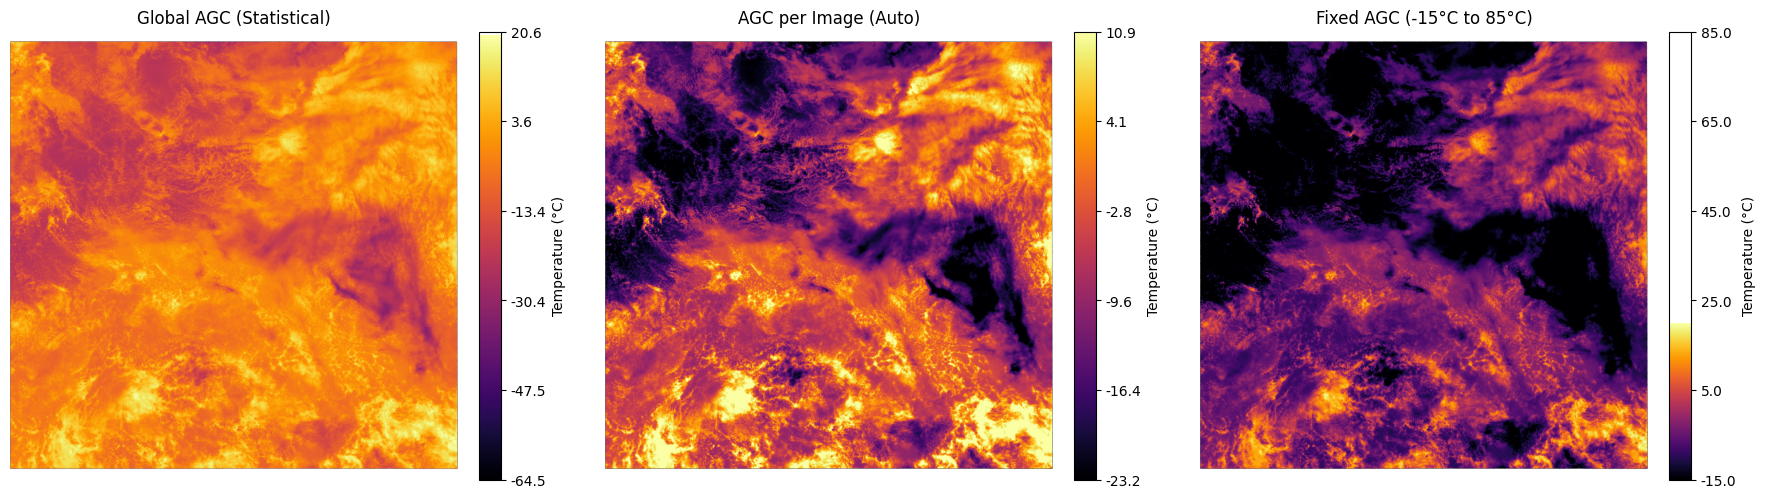

In [38]:
plt.figure(figsize=(18, 5))
ticks = np.linspace(0, 1, 6)

# ---------- Global AGC ----------
plt.subplot(1, 3, 1)
im1 = plt.imshow(BTn_global, cmap="inferno")
plt.title("Global AGC (Statistical)")
plt.axis("off")

cbar1 = plt.colorbar(im1, fraction=0.046, pad=0.04)
labels = (T_low + ticks * (T_high - T_low)) - 273.15
cbar1.set_ticks(ticks)
cbar1.set_ticklabels([f"{t:.1f}" for t in labels])
cbar1.set_label("Temperature (°C)")

# ---------- AGC per Image (Auto) ----------
plt.subplot(1, 3, 2)
im2 = plt.imshow(BTn_auto, cmap="inferno")
plt.title("AGC per Image (Auto)")
plt.axis("off")

cbar2 = plt.colorbar(im2, fraction=0.046, pad=0.04)
labels = (a_min + ticks * (a_max - a_min)) - 273.15
cbar2.set_ticks(ticks)
cbar2.set_ticklabels([f"{t:.1f}" for t in labels])
cbar2.set_label("Temperature (°C)")

# ---------- Fixed AGC ----------
plt.subplot(1, 3, 3)
im3 = plt.imshow(BTn_fixed, cmap="inferno")
plt.title("Fixed AGC (-15°C to 85°C)")
plt.axis("off")

cbar3 = plt.colorbar(im3, fraction=0.046, pad=0.04)
labels = (T_fixed_min + ticks * (T_fixed_max - T_fixed_min)) - 273.15
cbar3.set_ticks(ticks)
cbar3.set_ticklabels([f"{t:.1f}" for t in labels])
cbar3.set_label("Temperature (°C)")

plt.tight_layout()
plt.show()

## **Processing and Saving Batch of Images**

In [46]:
# Paths
BASE_DIR = "/content/drive/MyDrive/Dataset Wildfire/Pre-Processed_Images/RAW_Images"

DIRS = {
    "comparison": os.path.join(BASE_DIR, "comparison_plots"),

    "global_img": os.path.join(BASE_DIR, "agc_global/images"),
    "global_meta": os.path.join(BASE_DIR, "agc_global/metadata"),

    "auto_img": os.path.join(BASE_DIR, "agc_per_image/images"),
    "auto_meta": os.path.join(BASE_DIR, "agc_per_image/metadata"),

    "fixed_img": os.path.join(BASE_DIR, "agc_fixed/images"),
    "fixed_meta": os.path.join(BASE_DIR, "agc_fixed/metadata"),
}

for d in DIRS.values():
    os.makedirs(d, exist_ok=True)

In [47]:
def save_comparison_plot(scene, scene_id, T_low, T_high, out_path, cmap="inferno"):
    T = load_bt(scene)
    if T is None:
        return

    # 1) Global
    Tn_global = apply_agc(T, T_low, T_high)

    # 2) Auto
    Tli, Thi = compute_percentiles(T, 2, 98)
    Tn_auto = apply_agc(T, Tli, Thi)

    # 3) Fixed
    T_fixed_min = -15.0 + 273.15
    T_fixed_max = 85.0 + 273.15
    Tn_fixed = apply_agc(T, T_fixed_min, T_fixed_max)

    # PLOT
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    ticks = np.linspace(0, 1, 6)

    # --- Global ---
    im1 = axes[0].imshow(Tn_global, cmap=cmap)
    axes[0].set_title("Global AGC (Statistical)")
    axes[0].axis("off")
    cbar1 = fig.colorbar(im1, ax=axes[0], fraction=0.046, pad=0.04)
    labels = (T_low + ticks * (T_high - T_low)) - 273.15
    cbar1.set_ticks(ticks)
    cbar1.set_ticklabels([f"{t:.1f}" for t in labels])
    cbar1.set_label("Temperature (°C)")

    # --- Auto ---
    im2 = axes[1].imshow(Tn_auto, cmap=cmap)
    axes[1].set_title("AGC per Image (Auto)")
    axes[1].axis("off")
    cbar2 = fig.colorbar(im2, ax=axes[1], fraction=0.046, pad=0.04)
    labels = (Tli + ticks * (Thi - Tli)) - 273.15
    cbar2.set_ticks(ticks)
    cbar2.set_ticklabels([f"{t:.1f}" for t in labels])
    cbar2.set_label("Temperature (°C)")

    # --- Fixed ---
    im3 = axes[2].imshow(Tn_fixed, cmap=cmap)
    axes[2].set_title("Fixed AGC (-15°C to 85°C)")
    axes[2].axis("off")
    cbar3 = fig.colorbar(im3, ax=axes[2], fraction=0.046, pad=0.04)
    labels = (T_fixed_min + ticks * (T_fixed_max - T_fixed_min)) - 273.15
    cbar3.set_ticks(ticks)
    cbar3.set_ticklabels([f"{t:.1f}" for t in labels])
    cbar3.set_label("Temperature (°C)")

    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.close(fig)

In [48]:
def save_agc(scene, scene_id, mode, img_path, meta_path, T_low=None, T_high=None, cmap="inferno"):
    BT = load_bt(scene)
    if BT is None:
        return

    if mode == "GLOBAL":
        Tmin, Tmax = T_low, T_high
    elif mode == "AUTO":
        Tmin, Tmax = compute_percentiles(BT, 2, 98)
    elif mode == "FIXED":
        Tmin, Tmax = T_fixed_min, T_fixed_max
    else:
        raise ValueError("Invalid AGC mode")

    BTn = apply_agc(BT, Tmin, Tmax)
    rgb = thermal_to_rgb(BTn, cmap=cmap)

    plt.imsave(img_path, rgb)

    save_metadata(meta_path, {
        "scene_id": scene_id,
        "mode": f"AGC_{mode}",

        "T_min_K": float(Tmin),
        "T_max_K": float(Tmax),
        "T_min_C": float(Tmin - 273.15),
        "T_max_C": float(Tmax - 273.15),

        "date": scene.get("date"),
        "cloud_cover": scene.get("cloud_cover"),
        "note": "Brightness Temperature (apparent at sensor). Not surface temperature."
    })

In [49]:
# Processing Images
for scene_id, scene in tqdm(scene_index.items(), desc="Saving Results"):
    save_comparison_plot(
        scene, scene_id, T_low, T_high,
        os.path.join(DIRS["comparison"], f"{scene_id}_comparison.png")
    )

    save_agc(scene, scene_id, "GLOBAL",
             img_path=os.path.join(DIRS["global_img"], f"{scene_id}_global.png"),
             meta_path=os.path.join(DIRS["global_meta"], f"{scene_id}_global.json"),
             T_low=T_low, T_high=T_high)

    save_agc(scene, scene_id, "AUTO",
             img_path=os.path.join(DIRS["auto_img"], f"{scene_id}_auto.png"),
             meta_path=os.path.join(DIRS["auto_meta"], f"{scene_id}_auto.json"))

    save_agc(scene, scene_id, "FIXED",
             img_path=os.path.join(DIRS["fixed_img"], f"{scene_id}_fixed.png"),
             meta_path=os.path.join(DIRS["fixed_meta"], f"{scene_id}_fixed.json"))

Saving Results: 100%|██████████| 35/35 [09:57<00:00, 17.08s/it]


# **Post-Processing Images**

## **Importing Images**

In [50]:
# Input Images
BASE_INPUT = "/content/drive/MyDrive/Dataset Wildfire/Pre-Processed_Images/RAW_Images"

INPUT_DIRS = {
    "GLOBAL": os.path.join(BASE_INPUT, "agc_global/images"),
    "AUTO":   os.path.join(BASE_INPUT, "agc_per_image/images"),
    "FIXED":  os.path.join(BASE_INPUT, "agc_fixed/images"),
}

In [51]:
# Output Path
BASE_OUTPUT = "/content/drive/MyDrive/Dataset Wildfire/Post-Processed_Images/RAW_Images"

OUTPUT_DIRS = {
    "A": {
        "GLOBAL": os.path.join(BASE_OUTPUT, "profile_A/global"),
        "AUTO":   os.path.join(BASE_OUTPUT, "profile_A/auto"),
        "FIXED":  os.path.join(BASE_OUTPUT, "profile_A/fixed"),
    },
    "B": {
        "GLOBAL": os.path.join(BASE_OUTPUT, "profile_B/global"),
        "AUTO":   os.path.join(BASE_OUTPUT, "profile_B/auto"),
        "FIXED":  os.path.join(BASE_OUTPUT, "profile_B/fixed"),
    },
    "C": {
        "GLOBAL": os.path.join(BASE_OUTPUT, "profile_C/global"),
        "AUTO":   os.path.join(BASE_OUTPUT, "profile_C/auto"),
        "FIXED":  os.path.join(BASE_OUTPUT, "profile_C/fixed"),
    }
}

for profile in OUTPUT_DIRS.values():
    for d in profile.values():
        os.makedirs(d, exist_ok=True)

## **Processing Functions**

In [52]:
# Lepton 3.5 Image Size
LEPTON_W = 160
LEPTON_H = 120

In [53]:
def split_into_4_regions(img):
    h, w, _ = img.shape
    h2, w2 = h // 2, w // 2

    return [
        img[0:h2,   0:w2],
        img[0:h2,   w2:w],
        img[h2:h,   0:w2],
        img[h2:h,   w2:w],
    ]

In [54]:
def resize_to_lepton(img):
    return cv2.resize(
        img,
        (LEPTON_W, LEPTON_H),
        interpolation=cv2.INTER_AREA
    )

In [55]:
def crop_valid_region(img, threshold=10):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

    # Mask for Valid Regions
    mask = gray > threshold

    coords = np.column_stack(np.where(mask))
    if coords.size == 0:
        return img

    y0, x0 = coords.min(axis=0)
    y1, x1 = coords.max(axis=0)

    return img[y0:y1+1, x0:x1+1]

In [56]:
def add_thermal_noise(img_rgb, sigma_celsius=2.5):
    img = img_rgb.astype(np.float32) / 255.0
    noise = np.random.normal(
        0.0,
        sigma_celsius / 100.0,
        size=img.shape
    )
    noisy = np.clip(img + noise, 0.0, 1.0)
    return (noisy * 255).astype(np.uint8)

In [57]:
def apply_optical_blur(img_rgb, sigma_px=1.0):
    k = int(2 * round(2 * sigma_px) + 1)
    return cv2.GaussianBlur(img_rgb, (k, k), sigmaX=sigma_px)

In [58]:
def generate_fpn(shape, strength=0.06):
    h, w, _ = shape
    return np.random.normal(0.0, strength, size=(h, w, 1))

def apply_fpn(img_rgb, fpn_map, factor=1.0):
    img = img_rgb.astype(np.float32) / 255.0
    img = img + factor * fpn_map
    img = np.clip(img, 0.0, 1.0)
    return (img * 255).astype(np.uint8)

## **Processing Images**

In [59]:
# Noise Pattern
FPN_MAP = generate_fpn((LEPTON_H, LEPTON_W, 3), strength=0.075)

In [60]:
def simulate_profile_A(img):
    img = resize_to_lepton(img)
    img = add_thermal_noise(img, sigma_celsius=1.0)
    img = apply_optical_blur(img, sigma_px=0.9)

    return np.clip(img, 0, 255).astype(np.uint8)

In [61]:
def simulate_profile_B(img):
    img = resize_to_lepton(img)
    img = add_thermal_noise(img, sigma_celsius=1.5)
    img = apply_optical_blur(img, sigma_px=1.0)
    img = apply_fpn(img, FPN_MAP, factor=0.8)

    return np.clip(img, 0, 255).astype(np.uint8)

In [62]:
def simulate_profile_C(img):
    img = resize_to_lepton(img)
    img = add_thermal_noise(img, sigma_celsius=3.5)
    img = apply_optical_blur(img, sigma_px=1.5)
    img = apply_fpn(img, FPN_MAP, factor=1.5)

    return np.clip(img, 0, 255).astype(np.uint8)

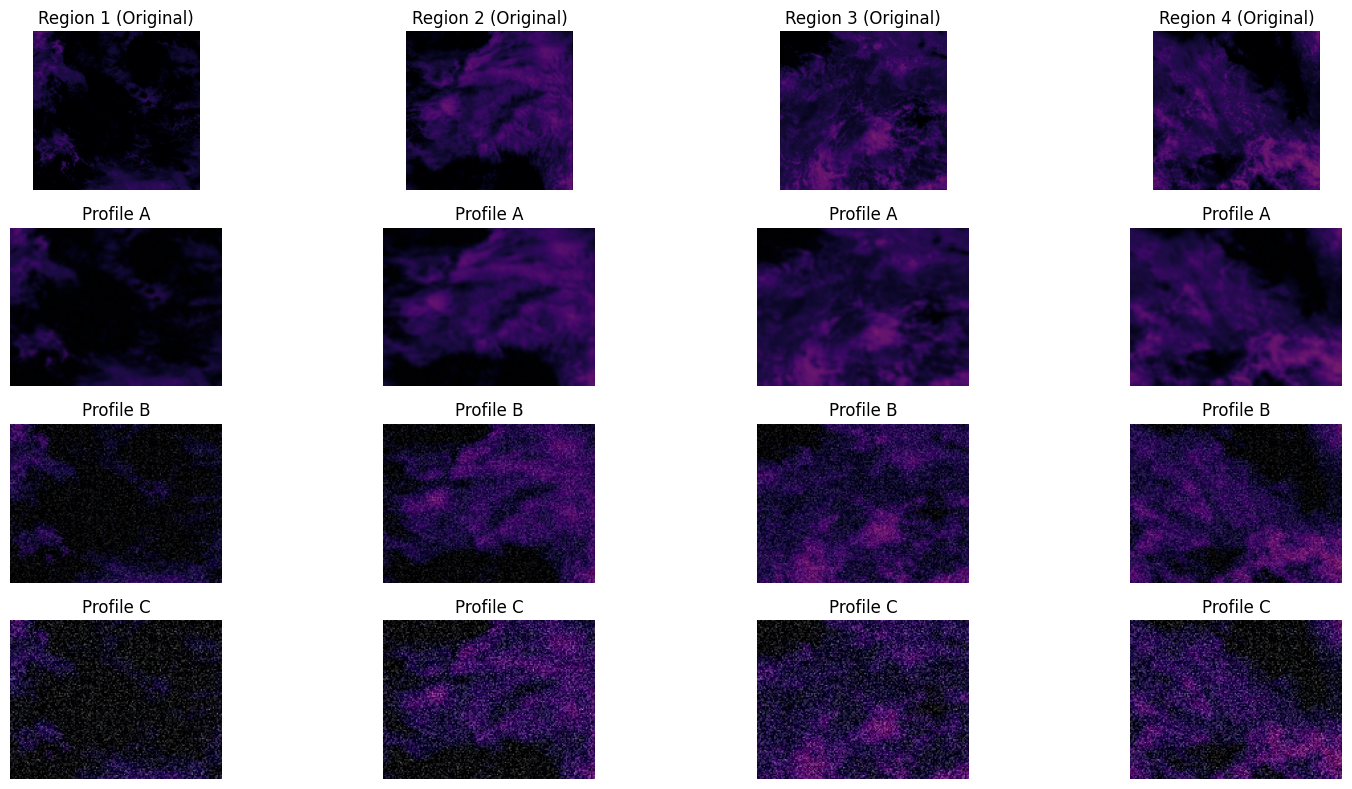

In [63]:
# Sample Image
sample_path = glob(os.path.join(INPUT_DIRS["FIXED"], "*.png"))[0]
img = cv2.cvtColor(cv2.imread(sample_path), cv2.COLOR_BGR2RGB)

img_clean = crop_valid_region(img)
regions = split_into_4_regions(img_clean)

plt.figure(figsize=(16, 8))

for i, region in enumerate(regions):
    outA = simulate_profile_A(region)
    outB = simulate_profile_B(region)
    outC = simulate_profile_C(region)

    plt.subplot(4, 4, i + 1)
    plt.imshow(region)
    plt.title(f"Region {i+1} (Original)")
    plt.axis("off")

    plt.subplot(4, 4, i + 5)
    plt.imshow(outA)
    plt.title(f"Profile A")
    plt.axis("off")

    plt.subplot(4, 4, i + 9)
    plt.imshow(outB)
    plt.title(f"Profile B")
    plt.axis("off")

    plt.subplot(4, 4, i + 13)
    plt.imshow(outC)
    plt.title(f"Profile C")
    plt.axis("off")

plt.tight_layout()
plt.show()

## **Saving Images**

In [64]:
for mode, in_dir in INPUT_DIRS.items():
    images = sorted(glob(os.path.join(in_dir, "*.png")))

    for img_path in tqdm(images, desc=f"Processing {mode}", leave=True):
        base = os.path.splitext(os.path.basename(img_path))[0]

        img_bgr = cv2.imread(img_path)
        if img_bgr is None:
            continue

        img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Removing Black Areas
        img_clean = crop_valid_region(img)

        # Checking Size
        h, w, _ = img_clean.shape
        if h < 20 or w < 20:
            continue

        regions = split_into_4_regions(img_clean)

        for idx, region in enumerate(regions):
            # Profile A
            outA = simulate_profile_A(region)
            cv2.imwrite(
                os.path.join(
                    OUTPUT_DIRS["A"][mode],
                    f"{base}_r{idx}_A.png"
                ),
                cv2.cvtColor(outA, cv2.COLOR_RGB2BGR)
            )

            # Profile B
            outB = simulate_profile_B(region)
            cv2.imwrite(
                os.path.join(
                    OUTPUT_DIRS["B"][mode],
                    f"{base}_r{idx}_B.png"
                ),
                cv2.cvtColor(outB, cv2.COLOR_RGB2BGR)
            )

            # Profile C
            outC = simulate_profile_C(region)
            cv2.imwrite(
                os.path.join(
                    OUTPUT_DIRS["C"][mode],
                    f"{base}_r{idx}_C.png"
                ),
                cv2.cvtColor(outC, cv2.COLOR_RGB2BGR)
            )

Processing FIXED: 100%|██████████| 35/35 [00:11<00:00,  3.04it/s]
